# Classification models: Logistic regression

Classification models are designed to help us answer simple but important questions: is it “yes” or “no,” true or false?  
**Logistic regression** is one of the most common approaches for this kind of task, and it’s widely used when we want to predict outcomes based on input features. In this study, we apply logistic regression to a practical case: **predicting fire ignition**.  
  
To illustrate the method, we rely on a dataset related to fire occurrence, with the option of using similar datasets available directly from the scikit-learn library in Python.   

> **Other data can be find [here](https://scikit-learn.org/stable/datasets.html) (from scikit-learn) or [here](https://www.kaggle.com/datasets) (from kaggle).**

In [3]:
# Import librairies and data for the whole notebook
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.special import expit

from sklearn import preprocessing, linear_model
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc, root_mean_squared_error,
    ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve
)

from classification_models.preprocess import PreprocessData

%reload_ext autoreload
%autoreload 2

## **Step 1 - Data preprocessing**

The first step in our workflow is to open the dataset, explore its structure, and prepare it for modeling. This stage is crucial, since the quality of the data has a direct impact on the **performance** and **reliability** of the model.  
  
To set up the classification task, we organize the dataset into two separate dataframes:  
- the input features
- the target variable

### **1.1 - Open the dataset**

In [4]:
preprocess_func = PreprocessData(Path("../database/weatherAUS.csv"))
raw_df = preprocess_func.df
raw_df

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,day,week,month,year
Date,,,,,,,,,,,,,,,,,,,,,
2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,...,8.0,NaN,16.9,21.8,No,No,1.0,49.0,12.0,2008.0
2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,NaN,NaN,17.2,24.3,No,No,2.0,49.0,12.0,2008.0
2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,...,NaN,2.0,21.0,23.2,No,No,3.0,49.0,12.0,2008.0
2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,...,NaN,NaN,18.1,26.5,No,No,4.0,49.0,12.0,2008.0
2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,...,7.0,8.0,17.8,29.7,No,No,5.0,49.0,12.0,2008.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-06-21,Uluru,2.8,23.4,0.0,NaN,NaN,E,31.0,SE,ENE,...,NaN,NaN,10.1,22.4,No,No,21.0,25.0,6.0,2017.0
2017-06-22,Uluru,3.6,25.3,0.0,NaN,NaN,NNW,22.0,SE,N,...,NaN,NaN,10.9,24.5,No,No,22.0,25.0,6.0,2017.0
2017-06-23,Uluru,5.4,26.9,0.0,NaN,NaN,N,37.0,SE,WNW,...,NaN,NaN,12.5,26.1,No,No,23.0,25.0,6.0,2017.0


### **1.2 - Description of the data**

The Weather Australia dataset is a collection of historical weather observations recorded at various weather stations across Australia. It contains a comprehensive set of meteorological variables, including temperature, rainfall, humidity, wind speed, atmospheric pressure, and more. The dataset is widely used by researchers, meteorologists, and data scientists for weather analysis, forecasting, and climate studies.
  
| Column name | Definition | Unit |
|--------|-----------|--------|
| `Date`| Date of the weather observation | No unity |
| `Location` | Name or code of the weather station | str |
| `MinTemp` | Minimum temperature of the day |  Degrees celcius (°C) |
| `MaxTemp` | Maximum temperature of the day  |  Degrees celcius (°C) |
| `Rainfall` |  Amount of rainfall of the day | Millimeters (mm) |
| `Evaporation` | Water evaporation | Millimeters (mm) |
| `Sunshine` | Hours of bright sunshine recorded | No unity |
| `WindGustDir` | Maximum wind gust speed |  Degrees celsius (°C)  |
| `WindGustSpeed` | Maximum wind gust speed | Kilometers per hour (km/h) |
| `WindDir{time}` | Average wind direction at 9am and 3 pm | Degrees (°)  |
| `WindSpeed{time}` | Wind speed at at 9am and 3 pm | Kilometers per hour (km/h) |
| `Humidity{time}` | Average relative humidity at 9am and 3 pm | % |
| `Pressure{time}` | Atmospheric pressure at 9am and 3 pm | hPa |
| `Cloud{time}` | Cloud cover | % |
| `Temp{time}` | Temperature at 9am and 3 pm | Degrees celsius (°C) |
| `RainToday` | Binary variable indicating if it rained today (1 for "Yes", 0 for "No") | No unity |
| `RainTomorrow` | Binary target variable indicating if it will rain tomorrow (1 for "Yes", 0 for "No") | No unity |


### **1.3 - Data inspection and process**

Before moving forward with modeling, it is essential to begin with a general inspection of the dataset. This step ensures that the data are consistent, correctly formatted, and free from obvious errors. Checking aspects such as **units**, **data types**, and **overall coherence** is critical, since any issues here can directly affect the quality of the model.

Once the dataset has been reviewed, several preprocessing actions may be required, including:

- adjusting data types
- handling missing values (fillna)
- converting columns
- identifying potential outliers (for example, negative values in precipitation records).

In our case, the inspection highlights two immediate tasks: converting certain columns and filling missing values. Additionally, we note that six columns are currently stored as object type, which will need to be addressed in the next stage of preprocessing.

In [5]:
# General informations functions
raw_df.info()
raw_df.describe()

# Check the number of nan values
raw_df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 145460 entries, 2008-12-01 to 2017-06-25
Data columns (total 26 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Location       145460 non-null  object 
 1   MinTemp        143975 non-null  float64
 2   MaxTemp        144199 non-null  float64
 3   Rainfall       142199 non-null  float64
 4   Evaporation    82670 non-null   float64
 5   Sunshine       75625 non-null   float64
 6   WindGustDir    135134 non-null  object 
 7   WindGustSpeed  135197 non-null  float64
 8   WindDir9am     134894 non-null  object 
 9   WindDir3pm     141232 non-null  object 
 10  WindSpeed9am   143693 non-null  float64
 11  WindSpeed3pm   142398 non-null  float64
 12  Humidity9am    142806 non-null  float64
 13  Humidity3pm    140953 non-null  float64
 14  Pressure9am    130395 non-null  float64
 15  Pressure3pm    130432 non-null  float64
 16  Cloud9am       89572 non-null   float64
 17  Cloud3pm     

Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
day                  0
week                 0
month                0
year                 0
dtype: int64

#### **1.3.1 - Handling Missing Values**

During inspection, we observed that the dataset contains a significant number of missing (NaN) entries. To ensure the model  
can learn effectively, it is necessary to define a consistent strategy for **filling these gaps**.

For the numerical variables, our approach is to replace missing values with the average value of the corresponding week. This  
method helps preserve seasonal and short-term weather patterns while avoiding bias from global averages.  

The following columns are treated in this way:
- **``MinTemp``**
- **``MaxTemp``**
- **``Rainfall``**
- **``Evaporation``**
- **``Sunshine``**
- **``WindGustSpeed``**
- **``WindSpeed9am``** and **``WindSpeed3pm``**
- **``Pressure9am``** and **``Pressure3pm``**
- **``Cloud9am``**
- **``Cloud3pm``**
- **``Temp9am``**
- **``Temp3pm``**

For the categorical variables RainToday and RainTomorrow, we apply a rule-based transformation derived from rainfall measurements:

- if Rainfall ≥ 1, then RainToday = "Yes"
- if Rainfall < 1, then RainToday = "No".

The same logic is applied to RainTomorrow, but using rainfall data shifted by one day to reflect the forecast.

---

This preprocessing ensures that both numerical and categorical features are **consistent**, **interpretable**, and **ready for modeling**.

In [6]:
regex = "Location|week|Evaporation|Rainfall|Sunshine|WindGustSpeed\
    |.*(WindSpeed|Temp).*|(Humidity|Pressure|Cloud).*"

preprocess_func.fill_nan_using_avg(raw_df, regex)
preprocess_func.fill_nan_using_rain()

After selecting the relevant columns and filling missing entries with weekly averages, we still observe some **NaN values**. This occurs  
because, in certain cases, no measurements were recorded for an entire week or longer, making the weekly mean itself undefined.

The remaining missing values are simply dropped. Although this reduces the dataset size, it allows us to retain all features without  
introducing artificial estimates. For example, the column **``Sunshine``** shows the highest proportion of missing data at around 36%.  
Even in this case, the dataset remains big enough to proceed with modeling while keeping the full set of variables intact.

In [7]:
preprocess_func.df.isna().sum()

Location             0
MinTemp              0
MaxTemp              0
Rainfall             0
Evaporation      46811
Sunshine         53183
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am         0
WindSpeed3pm         0
Humidity9am          0
Humidity3pm          7
Pressure9am      12119
Pressure3pm      12119
Cloud9am         34974
Cloud3pm         34974
Temp9am              0
Temp3pm              7
RainToday            0
RainTomorrow         0
day                  0
week                 0
month                0
year                 0
dtype: int64

In [8]:
df = preprocess_func.df
df.dropna(inplace=True)
df.reset_index(inplace=True)
df.isna().sum()

Date             0
Location         0
MinTemp          0
MaxTemp          0
Rainfall         0
Evaporation      0
Sunshine         0
WindGustDir      0
WindGustSpeed    0
WindDir9am       0
WindDir3pm       0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Cloud9am         0
Cloud3pm         0
Temp9am          0
Temp3pm          0
RainToday        0
RainTomorrow     0
day              0
week             0
month            0
year             0
dtype: int64

#### **1.3.2 - Check for outliers**

To ensure the dataset remains consistent, we also need to check for potential **outliers** in key features. Outliers can distort  
the learning process and reduce the reliability of the model if left untreated. One straightforward way to handle them is by  
using the clip function, which restricts values to a defined range.

In this example, we apply clipping rules using ``clip`` to guarantee that:

- **``Rainfall``** and **``Sunshine``** contain only values greater than 0
- **``Cloud9am``** and **``Cloud3pm``** remain within the valid range of $[0, 100]$

There are more advanced techniques for detecting and managing outliers, such as using the Interquartile Range (IQR) method.  
For further reading on outlier detection strategies, you can explore this [website](https://medium.com/@shivakumar28999/removing-outliers-with-scikit-learn-e52848eb7a9d).


In [9]:
col_stric_positive = ["Rainfall", "Sunshine"]
df[col_stric_positive] = df[col_stric_positive].clip(lower=0)

col_percentage = ["Cloud9am", "Cloud3pm"]
df[col_percentage] = df[col_percentage].clip(lower=0, upper=100)

#### **1.3.3 - Convert data**

Before building the classification model, we need to transform the **categorical variables** RainToday and RainTomorrow.  
These columns currently contain the string values "Yes" and "No", but machine learning algorithms require **numerical inputs**.

The first step is to verify that these columns contain only the expected values. Once confirmed, we can convert them into  
binary format. If not, we need to manage the other values.

In [10]:
print(df["RainToday"].unique())
print(df["RainTomorrow"].unique())

['No' 'Yes']
['No' 'Yes']


Since we have verified that the data is consistent, we can now apply a **``LabelEncoder``** to the **``RainToday``** and **``RainTomorrow``** columns.  
A **``LabelEncoder``** is a simple tool that converts string-based categories into numeric format.

> **Warning**
>
> It creates an order! Here, we need to have this order, 1 means rain which is more important than 0 (no rain).  
> But sometimes, you do not want to create an order. We will see in a second what is the best option in that case.

In [11]:
label_enc = preprocessing.LabelEncoder()

df["RainToday"] = label_enc.fit_transform(df["RainToday"])
df["RainTomorrow"] = label_enc.fit_transform(df["RainTomorrow"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74921 entries, 0 to 74920
Data columns (total 27 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           74921 non-null  datetime64[ns]
 1   Location       74921 non-null  object        
 2   MinTemp        74921 non-null  float64       
 3   MaxTemp        74921 non-null  float64       
 4   Rainfall       74921 non-null  float64       
 5   Evaporation    74921 non-null  float64       
 6   Sunshine       74921 non-null  float64       
 7   WindGustDir    74921 non-null  object        
 8   WindGustSpeed  74921 non-null  float64       
 9   WindDir9am     74921 non-null  object        
 10  WindDir3pm     74921 non-null  object        
 11  WindSpeed9am   74921 non-null  float64       
 12  WindSpeed3pm   74921 non-null  float64       
 13  Humidity9am    74921 non-null  float64       
 14  Humidity3pm    74921 non-null  float64       
 15  Pressure9am    7492

**Good Job! You finished preprocessing data! Now, the dataset is ready for the next step: initializing the classification model.**

## **Step 2 - Classification Model**

The first step is to separate the useful features from the label column. Once this distinction is made, the dataset is divided into two subsets:

- train: used to fit the model and learn the relationships between features and the target.
- test: used to evaluate the model’s performance and verify its ability to generalize to unseen data.

After the split, the remaining categorical features must be encoded into numerical format so that the model can process them correctly. Encoding ensures that string-based values are transformed into integers or binary indicators, preserving their meaning while making them compatible with machine learning algorithms.

- **``WindGustDir``**
- **``WindDir9am``**
- **``WindDir3am``**

### **2.1 - Set up the model**

At this stage, we divide the dataset into two subsets: one for training the model and another for testing its performance. This separation is essential to evaluate how well the model generalizes to unseen data.

We use the function train_test_split from sklearn.model_selection to perform the split. This function allows us to specify:

> the proportion of data allocated to training and testing (**train_size** and **test_size**),
>
> a random seed (**random_state**) to ensure reproducibility of the split.

By setting these parameters, we can control the balance between training and evaluation while guaranteeing that results remain consistent across different runs.

In [12]:
# Set up the model: drop useless features and get the label
features = df.drop(columns=["RainTomorrow", "Location", "Date"])
target = df.RainTomorrow

# Get 20% of the dataset as a dataset of tests
X_train, X_test, y_train, y_test = train_test_split(
    features, target,
    test_size=0.2,
    train_size=0.8,
    random_state=42
)

### **2.2 - Encoding and scaling**

This step is crucial for classification models, since categorical data can not be used directly by most algorithms. If left untreated, categories may incorrectly influence one another or be misinterpreted as continuous values.

In practice, there are two common approaches to encoding categorical variables:

- **``LabelEncoder``**: assigns each category a unique integer value. This is simple and efficient, but it can  
introduce unintended ordinal relationships between categories.

- **``OneHotEncoder``**: creates a new binary column for each category, with values of 0 or 1 indicating the  
presence of that category. This avoids false ordering but increases the dimensionality of the dataset.

Here is an example of the result you can obtain if you use one of these encoder.
 
Reference:

| continents |
|-----------| 
| "Europe" |
| "Asia" |
| "Africa" |

After using a **``LabelEncoder``**:
| continents |
|----------|
| 0 |
| 1 |
| 2 |

After using a **``OneHotEncoder``**:

| continents_europe | continents_asia | continents_africa |
|----------|---------|-----------|
| 1 | 0 | 0 |
| 0 | 1 | 0 |
| 0 | 0 | 1 |

#### **2.2.1 - Encoding**

When working with **categorical features**, the encoder must first be fitted on the training data (X_train). This step identifies the categories present in each feature. Once fitted, the encoder can then transform the data into numerical arrays, typically represented as 0 and 1 values when using one-hot encoding.

This process be performed **ONLY** on the training set. This ensures that the model learns from the training data without being influenced by information from the test set. After fitting, the same encoder can be applied to transform the test data, maintaining consistency across both subsets.

In practice, this can be done using either **``fit_transform``** (which combines fitting and transforming in one step) or by calling fit followed by transform.

Additionally, the parameter **``handle_unknown``** plays a key role when applying the encoder to the test set. If a new, unseen category appears in the test data, this option determines how the encoder should handle it—for example, by ignoring the unknown value instead of raising an error.

In [13]:
# Initialisation encoder
encoder = preprocessing.OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# Select the columns to encode using OneHotEncoder
colonnes_to_encode = ["WindGustDir", "WindDir9am", "WindDir3pm"]

# Now we can use `transform` to create the new columns
X_train_encode = encoder.fit_transform(X_train[colonnes_to_encode])
X_test_encode = encoder.transform(X_test[colonnes_to_encode]) 

# Convert the array to dataframe
train_encoded_df = pd.DataFrame(
    X_train_encode,
    columns=encoder.get_feature_names_out(colonnes_to_encode),
    index=X_train.index
)
test_encoded_df = pd.DataFrame(
    X_test_encode,
    columns=encoder.get_feature_names_out(colonnes_to_encode),
    index=X_test.index
)

# We delete the initial columns and we replace them by the encoded one
X_train = pd.concat(
    [X_train.drop(columns=colonnes_to_encode), train_encoded_df],
    axis=1
)
X_test = pd.concat(
    [X_test.drop(columns=colonnes_to_encode), test_encoded_df],
    axis=1
)

X_train

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,...,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW
52939,13.5,17.1,0.0,8.000000,0.000000,46.0,30.0,28.0,93.0,92.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
46725,17.2,30.4,0.0,5.400000,10.900000,35.0,15.0,19.0,62.0,59.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9288,9.4,16.7,0.0,4.000000,6.900000,35.0,9.0,20.0,55.0,54.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
54162,3.9,17.2,0.0,1.571429,4.753061,28.0,6.0,17.0,98.0,72.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
67714,11.1,22.6,0.0,5.200000,5.300000,81.0,35.0,24.0,40.0,27.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37194,5.1,14.5,1.0,0.600000,0.800000,22.0,11.0,11.0,99.0,83.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6265,20.0,33.0,10.8,7.800000,12.300000,35.0,22.0,11.0,62.0,34.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
54886,18.4,29.9,0.0,9.600000,11.200000,43.0,20.0,22.0,62.0,43.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
860,8.2,19.3,0.0,4.000000,5.892857,33.0,15.0,19.0,70.0,36.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### **2.2.2 - Scaling**

When working with machine learning models those that rely on **spatial distribution** or **distance-based** measures, it is essential to scale the data. **Scaling** ensures that features are represented on comparable ranges, **preventing** variables with larger numerical values from **dominating** the model.  
 
[***MinMaxScaler***](https://medium.com/@iamkamleshrangi/how-min-max-scaler-works-9fbebb9347da)

$$
X_{new} = \frac{X_i - X_{min}}{X_{min} - X_{min}}
$$

where $X_i$ the value i, $X_{min}$ the minimum value of the dataset and $X_{max}$ the maximum value of the dataset.

[***StandardScaler***](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

$$
X_{new} = \frac{X_i - \mu}{s}
$$  

where $X_i$ the value i, $\mu$ the the mean of the training samples and $s$ is the standard deviation of the training samples.

[***RobustScaler***](https://hersanyagci.medium.com/feature-scaling-with-scikit-learn-for-data-science-8c4cbcf2daff)

$$
X_{new} = \frac{X_i - X_{mean}}{IQR}
$$

where $X_i$ the value i, $X_{mean}$ the median of the feature and $X_{IQR}$ the interquartile range ($Q_3 - Q_1$)

In [14]:
min_max_scaler = preprocessing.MinMaxScaler()

X_train_scaled = min_max_scaler.fit_transform(X_train)
X_test_scaled = min_max_scaler.transform(X_test)

To better understand the impact of scaling, we can compare the distribution of a feature before and after transformation. In this example, we plot the first column, **``MinTemp``**, from both the original training set (**``X_train``**) and the scaled version (**``X_train_scaled``**).

This visualization below highlights how scaling changes the range of values. By rescaling features, we ensure that all variables **contribute equally** to the model, rather than allowing those with larger numerical ranges to dominate.

Text(0.5, 1.0, 'After Scaling')

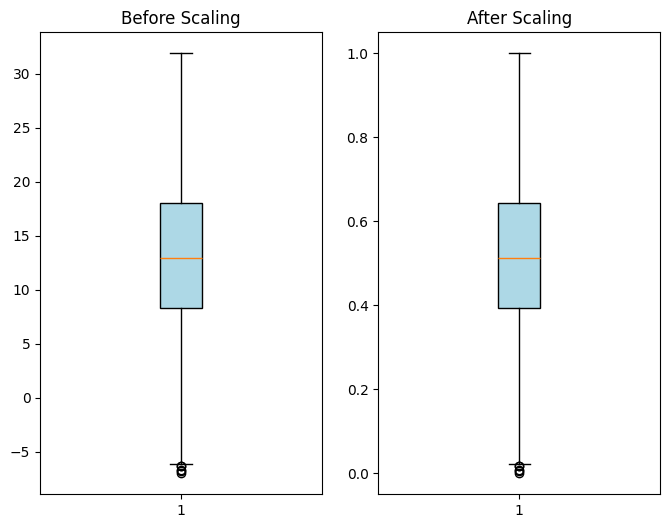

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(8, 6))

axes[0].boxplot(
    X_train.MinTemp,
    patch_artist=True,
    boxprops=dict(facecolor='lightblue')
)
axes[0].set_title("Before Scaling")
axes[1].boxplot(
    X_train_scaled[:, 0],
    patch_artist=True,
    boxprops=dict(facecolor='lightblue'),
)
axes[1].set_title("After Scaling")

> **A summary of all the useful functions for the preprocessing step is provided [here](https://scikit-learn.org/stable/api/sklearn.preprocessing.html).**

## **Step 3 - Logistic regression**

### **3.1 - Theory**

The goal of this model is to use weather-related features (such as temperature and rainfall) as inputs to predict a binary outcome, represented as either 0 or 1. The model relies on a **linear regression** approach, evaluating how closely the features relate to one another in order to separate the data into distinct classes.

The [***linear combination***](https://mrmint.fr/logistic-regression-machine-learning-introduction-simple) (1) is defined as below:

$$
\boxed{z = \theta_0 + \sum_{i=1}^{n} \theta_ix_i = \theta^Tx}
$$

where $x_i$ are the features and $\theta_i$ the weights of each features

---

Once the model computed this score for each sample, it applies a sigmoid function that classify values as either 0 or 1, using a threshold value (0.5 by default).

The [***sigmoid fonction***](https://mrmint.fr/logistic-regression-machine-learning-introduction-simple) (2) is define by the following formula:  

$$
\boxed{f(x) = \frac{1}{1 + e^{-\theta^Tx}} = h_\theta (x)}
$$

where $\theta^Tx$ is the result of the linear combination (1), 

---

To assess the quality of the model, we use **Binary Cross-Entropy**, also known as **log loss**. This loss function is commonly applied in **binary classification** tasks. It measures the **difference** between the true class labels (0 or 1) and the predicted probabilities generated by the model.  
A **lower** binary cross-entropy value indicates that the predicted probabilities are **closer** to the actual labels, meaning the model’s predictions align more accurately with reality. Conversely, **higher** values suggest greater **divergence** between predictions and true outcomes.  

Mathematically, [***Binary Cross-Entropy (BCE)***](https://www.geeksforgeeks.org/deep-learning/binary-cross-entropy-log-loss-for-binary-classification/) (or loss) is defined as:

$$
J(\theta) =
-\frac{1}{m} \sum_{i=1}^{m}
\left[ y_i \log(h_\theta(x^{(i)})) + (1 - y_i) \log(1 - h_\theta(x^{(i)})) \right] +
\boxed{\frac{\lambda}{2m} \sum_{j=1}^{m} \theta_j^2}
$$

where:  

$m$ is the number of observations  
$y_i$ the actual binary label {0 or 1} of the $i^{th}$ observation  
$h_\theta(x^{(i)})$ the predicted probability of the $i^{th}$ observation being in class 1    
$\theta$ the weight  
$\lambda = \frac{1}{C}$ with $C \in ]0:1]$

The highlighted part represents the optional **L2 regularization**, which is used to **prevent overfitting**. This discourages the model from assigning excessively large coefficients to individual features.  
 
Since the model’s output is expressed as a **probability** between 0 and 1, **minimizing** binary cross-entropy (log loss) during training **improves predictive accuracy**. This loss function ensures the model learns to distinguish effectively between the two classes.  
In addition, the hyperparameter $𝐶$ plays a key role in controlling regularization strength:

- small $\lambda$ (large $C$) $\rightarrow$ minimal regularization $\rightarrow$ model may overfit
- large $\lambda$ (small $C$) $\rightarrow$ strong regularization $\rightarrow$ model may underfit  
 
> You can find more informations on the [***official website***](https://scikit-learn.org/stable/modules/linear_model.html#multinomial-case). It provides diffrent regulation types and an explanation of the model.

### **3.2 - Initialize the model**

In [16]:
clf = linear_model.LogisticRegression(C=1.0) # default parameters

# Train the model using training values
clf.fit(X_train_scaled, y_train, sample_weight=None) # we can add weight (theta) to our features

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


Once we fit the model using train data, we can visualise the result using the equations (1) and (2) defined before on one feature: humidity for example.

$\rightarrow$ get the result of the linear equation (1)  
$\rightarrow$ use the equation (2) to get the score in a range $[0, 1]$  
$\rightarrow$ plot the result  

I put the general functions into the file ``classification_models/utils``

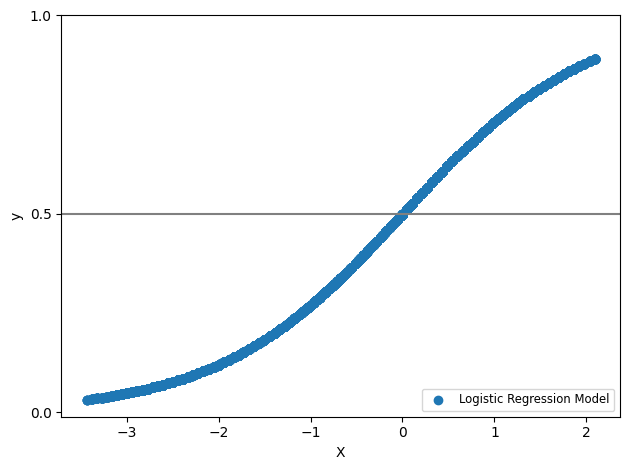

In [17]:
# Humidity9am
feature = 9
humidity = X_train_scaled[:, feature]

# score function
score = humidity * clf.coef_[0][feature] + clf.intercept_

# sigmoid function
sigmoid_result = 1 / (1 + np.exp(-score))

# or use the function expit from scipy.special 
sigmoid_result = expit(score)

plt.scatter(score, sigmoid_result, label="Logistic Regression Model")
plt.axhline(0.5, color=".5")
plt.ylabel("y")
plt.yticks([0, 0.5, 1])
plt.xlabel("X")
plt.legend(
    loc="lower right",
    fontsize="small"
)
plt.tight_layout()
plt.show()

## **Step 4 - Validate the model** 

Once we trained the model using the train dataset, we can now try to predict the result based on given features. This will show us if the model was trained correctly, if it did not under/overfit (or if it did not learn 'by heart' the train data).  

We have 2 differents choices to first get the results. We can use the function:
- **``predict``** - return if the result as either 0 or 1
- **``predict_proba``** - return the probability for each point to be as either 0 or 1  
 
The last method allows us to personalise the threshold value: instead of 0.5, we can be more strict and set it to 0.7.

In [18]:
y_pred = clf.predict(X_test_scaled)
probs = clf.predict_proba(X_test_scaled)
y_pred_new_threshold = np.where(probs[:, 1] > 0.7, 1, 0) # put the result of the roc curve

### **4.1 - Tools for classification metrics**

Now we have to evaluate the score of the prediction of the model to validate it or not. We have some metrics to help us:

[***RMSE***](https://scikit-learn.org/stable/modules/model_evaluation.html#mean-squared-error:~:text=available%20through%20the-,root_mean_squared_error,-function.)

$$
RMSE = \sqrt{ \frac{1}{n_{sample}} \sum_{i=0}^{n_{sample}-1}(y_i - \hat{y_i})² }
$$

where $\hat{y_i}$ is the predicted value of the $i$-th sample and $y_i$ the corresponding true value

[***Accuracy***](https://scikit-learn.org/stable/modules/model_evaluation.html#accuracy-score:~:text=value%200%20otherwise.-,3.4.4.2.%20Accuracy%20score,-%23)

It provides the proportion of correctly classified instances.

$$
accuracy(y, \hat{y}) = \frac{1}{n_{samples}} \sum_{i=0}^{n_{samples}-1} 1(\hat{y_i} = y_i)
$$

where $\hat{y_i}$ is the predicted value of the $i$-th sample, $y_i$ the corresponding true value and $1(x)$ the [***indicator function***](https://en.wikipedia.org/wiki/Indicator_function)

In other words, the equation above can become:

$$
accuracy = \frac{True\ positives + True\ negatives}{Total}
$$

[***Precision***](https://proceedings.neurips.cc/paper_files/paper/2015/file/33e8075e9970de0cfea955afd4644bb2-Paper.pdf)

It focuses on the accuracy of positive predictions

$$
precision = \frac{True\ positives}{True\ positives + False\ positives}
$$

[***Recall***](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html#sklearn.metrics.recall_score:~:text=The%20recall%20is%20the%20ratio%20tp%20/%20(tp%20%2B%20fn))

It measures the proportion of correctly predicted positive instances among all actual positive instances.

$$
recall = \frac{True\ positives}{True\ positives + False\ negatives}
$$

[***F1 Score***](https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/#:~:text=4.-,F1%20Score,-%3A%20F1%20score)

The F1 score can be interpreted as a harmonic mean of the precision and recall. We use harmonic mean because it penalizes extreme values more heavily than the arithmetic one. This is also better especially for imbalanced classificattion problems.

$$
F1 = \frac{2}{recall^{-1} + precision^{-1}} = \frac{2 TP}{2TP + FP + FN}
$$

where TP are the True positives, FP the false positives and FN the false negatives

All of the methods detailed above are sumurized in different functions from ``scikit-learn``.

[***Confusion matrix***](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html#sklearn.metrics.confusion_matrix)

Compute confusion matrix to evaluate the accuracy of a classification. It shows the number of values per category (true/false positives/negatives).

[***Classification report***](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html#sklearn.metrics.classification_report)

Build a text report showing the main classification metrics. It is a good summary of all the formula above (with $n$ the total amount of samples, $n_f$ the number of false and $n_t$ the number of true).  

|  | precision | recall | f1-score | support |
|--------|--------|---------|---------|--------|
| 0 | --- | --- | --- | $n_f$ |
| 1 | --- | --- | --- | $n_t$ |
| accuracy | --- | --- | --- | $n$ |
| macro avg | --- | --- | --- | $n$ |
| weighted avg | --- | --- | --- | $n$ |

In [19]:
# RMSE
rmse = root_mean_squared_error(y_test, y_pred)

# Confusion matrix (using scikit's library)
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix = pd.DataFrame(
    conf_matrix, 
    columns=["0 (Predicted)", "1 (Predicted)"],
    index=["0 (Real)", "1 (Real)"]
)

# Using pandas's library
conf_matrix_pandas = pd.crosstab(
    y_test,
    y_pred,
    rownames=['Real classes'],
    colnames=['Predicted classes']
)

print("RMSE: ", rmse, "\n")
print("From Scikit-learn's library: \n\n", conf_matrix, "\n\n")
print("From pandas' library: \n\n", conf_matrix_pandas)

RMSE:  0.4036867138796656 

From Scikit-learn's library: 

           0 (Predicted)  1 (Predicted)
0 (Real)          10675            702
1 (Real)           1740           1868 


From pandas' library: 

 Predicted classes      0     1
Real classes                  
0                  10675   702
1                   1740  1868


In [20]:
class_report = classification_report(y_test, y_pred)
print(class_report)

              precision    recall  f1-score   support

           0       0.86      0.94      0.90     11377
           1       0.73      0.52      0.60      3608

    accuracy                           0.84     14985
   macro avg       0.79      0.73      0.75     14985
weighted avg       0.83      0.84      0.83     14985



### **4.2 - Graph for classification metrics**

#### **4.2.1 - Confusion matrix**

You can easily visualised the results of the ``confusion_matrix`` function using a graph like the one just below.

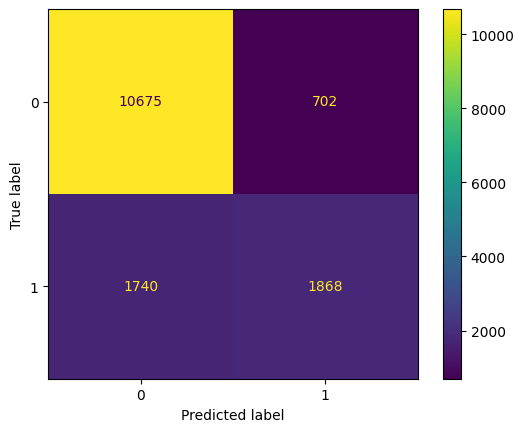

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=clf.classes_
)

#### **4.2.2 - ROC curve and the AUC (theory + graph)**

Another useful tool to inspect the results and get a better parameter for the computation of ``y_pred_new_threshold``: the <u>AUC-ROC</u>.  

The [***ROC***](https://en.wikipedia.org/wiki/Receiver_operating_characteristic) (for Receiver Operating Characteristic) curve illustrates the performance by changing the value of the threshold. It is created by plotting the fraction of true positives out of the positives (TPR) VS the fraction of false positives out of the negatives (FPR).  
  
The [***AUC***](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.auc.html) (for Area Under the Curve) is the area under the ROC curve (using trapezoid function). It gives a quick overview of the performance of the model.  

##### **Theory** - ROC

**First Step**: The Inputs  

This function needs the True binary labels and the predicted scores (as probabilities or a decision function).  

**Second Step:** The main process

Then, the function will classify the scores (descending order) and use all of these unique values as a threshold to classify predictions.


For example:  

```python
t = s_0 = 0.63 # first threshold value

1 if s_i >= t
0 if s_i < t
```

with t the threshold value (equal to $s_0$ for the first iteration) and $s_i$ the $i^{th}$ value of the scores  

**Third Step:** Rate computation  

Once the function checked all of the thresholds, it can compute the TPR and FPR as follow below:

$$
TPR = \frac{TP}{TP + FN}
$$

$$
FPR = \frac{FP}{FP + TN}
$$
with $TP$ the True Positives, $FP$ the False Positives, $TN$ the True Negatives and $FN$ the False Negatives

##### **Theory** - AUC

To compute this number, the function uses a trapezoid area for each pair of consecutive points.

Let's take these 2 points: $(x_i, y_i)$ and $(x_{i+1}, y_{i+1})$. The trapezoid area will be:  

$$
A_i = (x_{i+1} - x_i).\frac{y_i + y_{i+1}}{2}
$$

So the value of the AUC will be:

$$
AUC = \sum_{i=1}^{n-1} A_i
$$

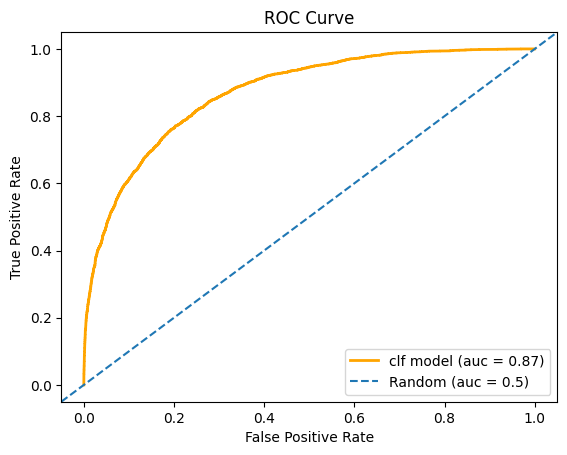

In [22]:
# We can use the following function to display directly
# RocCurveDisplay.from_predictions(y_test, probs[:, 1])


false_positive_rate, true_positive_rate, _ = roc_curve(
    y_test, probs[:, 1], pos_label=1
)
auc = auc(false_positive_rate, true_positive_rate)

plt.plot(
    false_positive_rate,
    true_positive_rate,
    color="orange",
    lw=2,
    label=f"clf model (auc = {round(auc, 2)})"
)
plt.axline(
    xy1=(0, 0), slope=1,
    linestyle="--",
    clip_on=True,
    label="Random (auc = 0.5)"
)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

> <u> **TIP n°1** </u>  
Model performance improves as the ROC curve approaches the upper-left corner, indicating fewer false positives and more true positives.

> <u> **TIP n°2** </u>  
An AUC value approaching 1 indicates excellent model performance, whereas an AUC near 0.5 suggests random classification.

#### **4.2.3 - Most important features (graph)**

The final validation metric introduced is **feature importance**, which provides a visual means of identifying the features that most strongly influence the model’s predictions. The method of obtaining this metric varies depending on the algorithm employed.

| Model | Code |
|---------|---------|
| Logistic Regression | model.coef_ |
| Decision Trees | model.feature_importances_ |
| Random Forest | model.feature_importances_ |
| XGBoost | get_score(importance_type="gain") |
| SVM | model.coef_ |
| KNN | permutation_importance |

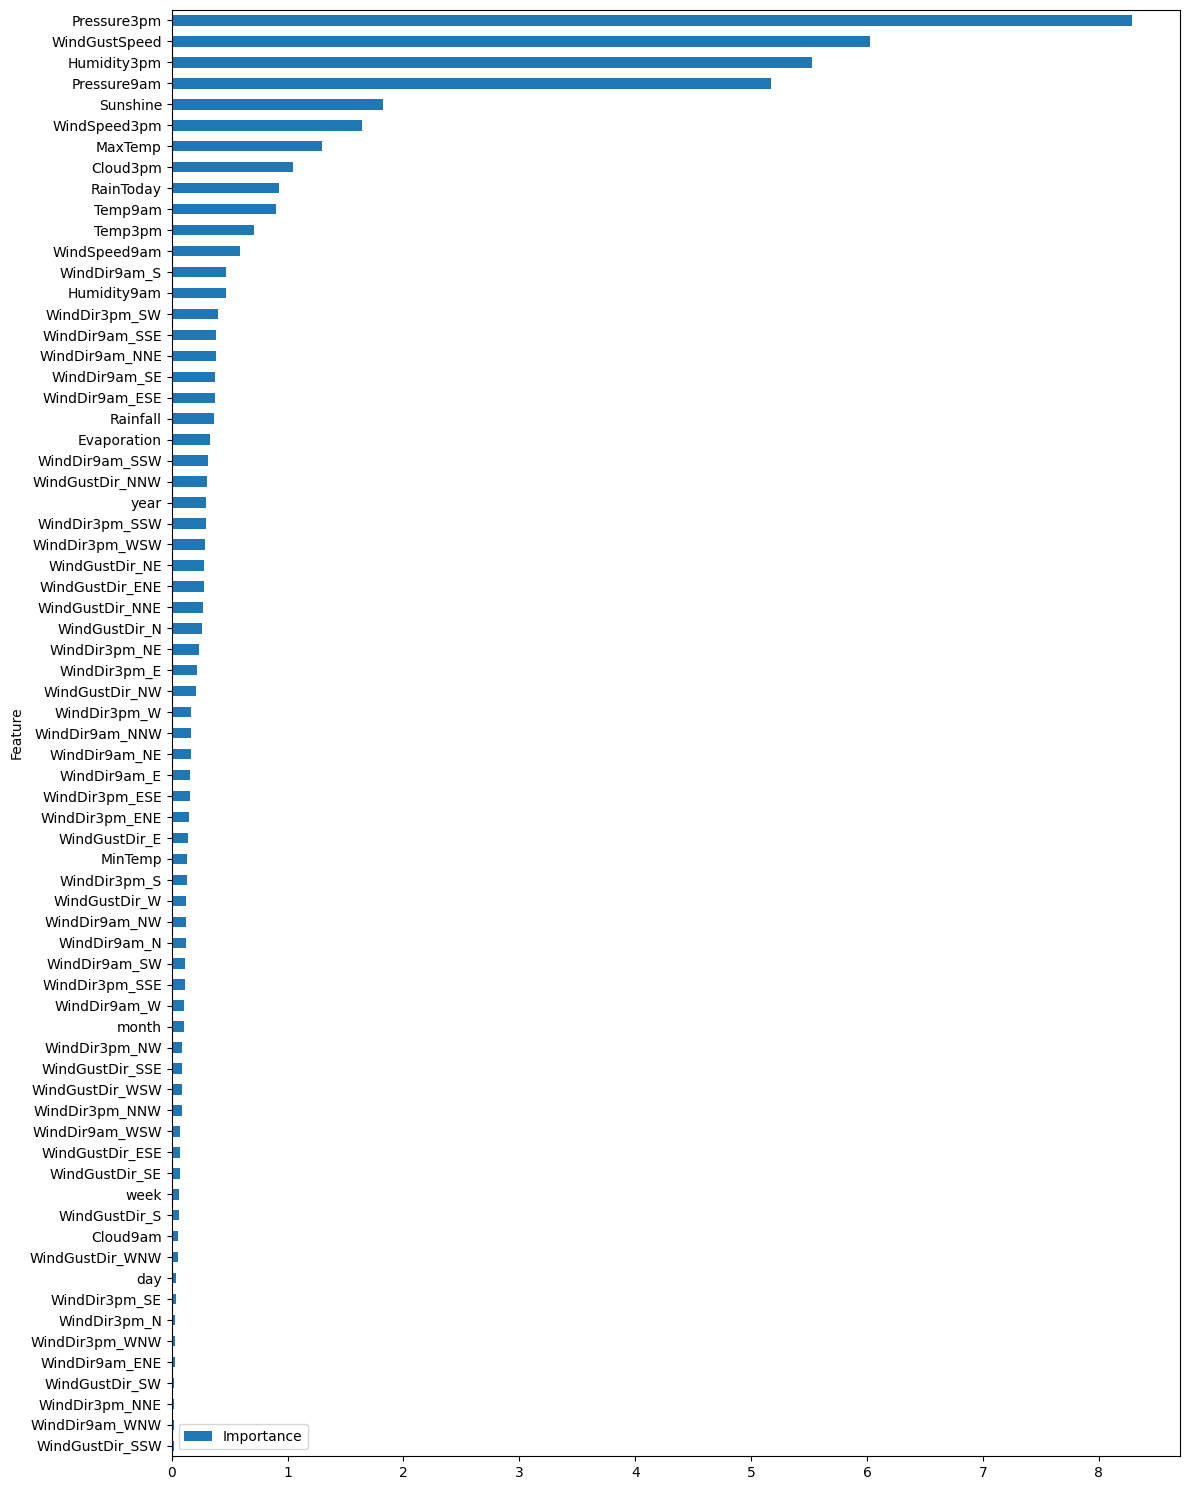

In [23]:
coefficients = clf.coef_

feature_importance = pd.DataFrame(
    {
        "Feature": X_train.columns,
        "Importance": np.abs(coefficients)[0, :]
    }
)
feature_importance = feature_importance.sort_values(
    "Importance", ascending=True
)

feature_importance.plot(
    x="Feature", y="Importance", kind="barh", figsize=(12, 15)
)
plt.tight_layout()

## **Step 5 - Save your model**

Once you have finalized your model and tuned the hyperparameters, you can save it using the library ``joblib``. This library is preferred over ``Pickle`` when working with models that handle **large amounts of data**.

After saving, the model can be loaded and reused as shown below:

In [ ]:
filepath = Path("../database/models/classification_model.pkl")  

joblib.dump(clf, filepath)

['..\\database\\models\\classification_model.pkl']

In [26]:
clf_loaded = joblib.load(filepath)
clf_loaded

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'
